# # 04 - Disease Risk Models (cross-validated)

> **This notebook is part of the SleepHealth-AI project.**
> It is executed against the *production* pipeline in `src/`, so every number
> below is the same number reported in `REPORT.md`, `results/metrics/metrics.json`
> and the Streamlit app. Each final cell **asserts** that agreement, so this
> notebook cannot silently drift from the shipped system.

**Setup:** run this notebook from the `notebooks/` folder. The first cell moves
the working directory to the repository root and puts `src/` on `sys.path`.


## What is being measured

Five binary risk tasks are trained and compared. For each one the same algorithm is fitted twice:

| Set | Features | Purpose |
|---|---|---|
| **Model A** | demographics only (`age`, `sex`, `BMI`, `waist`) | baseline |
| **Model B** | Model A **+ sleep features** | does sleep help? |

The difference **B - A** is the project's central scientific claim.

**Validation:** `RepeatedStratifiedKFold`, 5 folds x 3 repeats (15 splits). Reporting a single train/test split would make the score depend on which rows happened to land in the test set; repeating gives a distribution, so we can report a **95% confidence interval**.

**Leakage control:** the items that *define* a label are excluded from that label's features - e.g. snoring is removed from the OSA task, and `trouble_sleeping` is removed from the insomnia task.

In [1]:
# --- Reproducibility setup: run from notebooks/, work from the repo root ------
import os, sys, json
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":          # launched inside notebooks/
    ROOT = ROOT.parent
os.chdir(ROOT)                        # src/ scripts use repo-root-relative paths
sys.path.insert(0, str(ROOT / "src")) # so `import train_models` works

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Notebooks need the INLINE backend so plt.show() embeds the figure in the
# output. (The src/ scripts use "Agg" because they save PNGs to disk instead;
# copying that here would make every plot render as nothing.)
%matplotlib inline

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

print("repo root :", ROOT)
print("python    :", sys.version.split()[0])
print("pandas    :", pd.__version__)


repo root : C:\Users\Shubham\Desktop\SleepHealth-AI
python    : 3.13.2
pandas    : 3.0.6


In [2]:
import train_models as tm
from sklearn.model_selection import RepeatedStratifiedKFold

df = pd.read_csv(tm.DATA)
skf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

print('data   :', tm.DATA, df.shape)
print('tasks  :', list(tm.TASKS))

data   : data\processed\nhanes_sleep_health.csv (8282, 16)
tasks  : ['heart_disease', 'insomnia_risk', 'osa_risk']


### Leakage guard

Before training, confirm no label-defining feature slipped into its own task's feature list.

In [3]:
# A label must never be predictable from the item that defines it.
leak_rules = {
    'insomnia_risk': ['trouble_sleeping'],          # that IS SLQ050
    'osa_risk': ['snore_freq', 'witnessed_apnea_freq'],  # they define OSA
}
for task, forbidden in leak_rules.items():
    feats = tm.TASKS[task]['model_b']
    bad = [f for f in forbidden if f in feats]
    assert not bad, f'LEAKAGE: {bad} present in {task} features'
    print(f'OK - {task}: {forbidden} correctly excluded')

OK - insomnia_risk: ['trouble_sleeping'] correctly excluded
OK - osa_risk: ['snore_freq', 'witnessed_apnea_freq'] correctly excluded


### Train all tasks

This calls `cv_scores` - the *same* function the production pipeline uses - so the numbers below are identical to `results/metrics/metrics.json`.

In [4]:
rows = []
for task_name, task in tm.TASKS.items():
    d = df.dropna(subset=[task['target']]).copy()
    y = d[task['target']].astype(int)
    best = json.load(open('results/metrics/metrics.json', encoding='utf-8'))[
        'tasks'][task_name]['best_model']
    a = tm.cv_scores(task, task['model_a'], y, d[task['model_a']], best, skf)
    b = tm.cv_scores(task, task['model_b'], y, d[task['model_b']], best, skf)
    rows.append({
        'task': task_name, 'algorithm': best, 'n': len(d),
        'prevalence': round(float(y.mean()), 4),
        'A_demo_auc': a['roc_auc'], 'B_sleep_auc': b['roc_auc'],
        'delta': round(b['roc_auc'] - a['roc_auc'], 4),
        'B_auc_ci95': b['roc_auc_ci95'],
        'B_pr_auc': b['pr_auc'], 'B_f1': b['f1'],
        'B_recall': b['recall'], 'B_precision': b['precision'],
        'B_brier': b['brier'],
    })
results_df = pd.DataFrame(rows).set_index('task')
results_df

,algorithm,n,prevalence,A_demo_auc,B_sleep_auc,delta,B_auc_ci95,B_pr_auc,B_f1,B_recall,B_precision,B_brier
task,,,,,,,,,,,,
heart_disease,LogisticRegression,8281,0.0935,0.8027,0.8207,0.0180,"[0.7987, 0.839]",0.3048,0.3411,0.7868,0.2179,0.1801
insomnia_risk,LogisticRegression,8275,0.2865,0.6291,0.7072,0.0781,"[0.689, 0.7271]",0.4952,0.5202,0.6415,0.4377,0.2169
osa_risk,LogisticRegression,7444,0.3212,0.6791,0.6916,0.0125,"[0.663, 0.7096]",0.5005,0.5234,0.6227,0.4516,0.2222


### Cardiometabolic tasks (diabetes, hypertension)

These two use the same ablation design but are trained via the `evaluate_legacy` pipeline (RandomForest for diabetes, XGBoost for hypertension). Feature set B here adds sleep duration + trouble-sleeping.

In [5]:
import evaluate_legacy as el

LEGACY_A = ['age', 'gender_female', 'bmi', 'waist_circumference']
LEGACY_B = LEGACY_A + ['sleep_duration_hrs', 'trouble_sleeping']
legacy_specs = {
    'diabetes':     ('target_diabetes', 'RandomForest'),
    'hypertension': ('target_hypertension', 'XGBoost'),
}

legacy_rows = []
for name, (target, alg) in legacy_specs.items():
    y = df[target].astype(int)
    a = el.cv_binary(df[LEGACY_A], y, alg)
    b = el.cv_binary(df[LEGACY_B], y, alg)
    legacy_rows.append({
        'task': name, 'algorithm': alg, 'n': len(y),
        'prevalence': round(float(y.mean()), 4),
        'A_demo_auc': a['roc_auc'], 'B_sleep_auc': b['roc_auc'],
        'delta': round(b['roc_auc'] - a['roc_auc'], 4),
        'B_auc_ci95': b['roc_auc_ci95'], 'B_pr_auc': b['pr_auc'],
        'B_f1': b['f1'], 'B_recall': b['recall'],
        'B_precision': b['precision'], 'B_brier': b['brier'],
    })
legacy_df = pd.DataFrame(legacy_rows).set_index('task')
legacy_df

,algorithm,n,prevalence,A_demo_auc,B_sleep_auc,delta,B_auc_ci95,B_pr_auc,B_f1,B_recall,B_precision,B_brier
task,,,,,,,,,,,,
diabetes,RandomForest,8282,0.1591,0.7629,0.7704,0.0075,"[0.7401, 0.7955]",0.3543,0.4229,0.7183,0.2998,0.1745
hypertension,XGBoost,8282,0.3820,0.7744,0.7852,0.0108,"[0.7647, 0.8068]",0.6613,0.6211,0.6010,0.6431,0.1821


In [6]:
# ---- Combine all 5 tasks into one summary table -----------------------
combined = pd.concat([results_df, legacy_df])
combined[['algorithm','n','prevalence','A_demo_auc','B_sleep_auc','delta','B_auc_ci95','B_pr_auc','B_f1','B_recall','B_precision','B_brier']]

,algorithm,n,prevalence,A_demo_auc,B_sleep_auc,delta,B_auc_ci95,B_pr_auc,B_f1,B_recall,B_precision,B_brier
task,,,,,,,,,,,,
heart_disease,LogisticRegression,8281,0.0935,0.8027,0.8207,0.0180,"[0.7987, 0.839]",0.3048,0.3411,0.7868,0.2179,0.1801
insomnia_risk,LogisticRegression,8275,0.2865,0.6291,0.7072,0.0781,"[0.689, 0.7271]",0.4952,0.5202,0.6415,0.4377,0.2169
osa_risk,LogisticRegression,7444,0.3212,0.6791,0.6916,0.0125,"[0.663, 0.7096]",0.5005,0.5234,0.6227,0.4516,0.2222
diabetes,RandomForest,8282,0.1591,0.7629,0.7704,0.0075,"[0.7401, 0.7955]",0.3543,0.4229,0.7183,0.2998,0.1745
hypertension,XGBoost,8282,0.3820,0.7744,0.7852,0.0108,"[0.7647, 0.8068]",0.6613,0.6211,0.6010,0.6431,0.1821


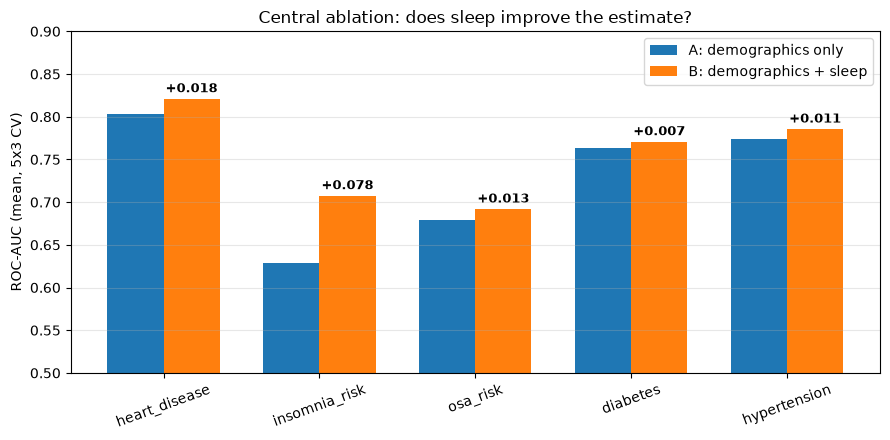

In [7]:
# ---- Ablation bar chart: does adding sleep features help? -------------
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(combined))
ax.bar(x - 0.18, combined['A_demo_auc'], 0.36, label='A: demographics only')
ax.bar(x + 0.18, combined['B_sleep_auc'], 0.36, label='B: demographics + sleep')
for i, d in enumerate(combined['delta']):
    ax.text(i + 0.18, combined['B_sleep_auc'].iloc[i] + 0.008,
            f'+{d:.3f}', ha='center', fontsize=9, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(combined.index, rotation=20)
ax.set_ylim(0.5, 0.9); ax.set_ylabel('ROC-AUC (mean, 5x3 CV)')
ax.set_title('Central ablation: does sleep improve the estimate?')
ax.legend(); ax.grid(alpha=0.3, axis='y')
plt.tight_layout(); plt.show()

### Verify against the shipped metrics

The notebook must agree with `metrics.json`. If a retrain ever changes these numbers, this cell fails loudly instead of showing a stale result.

In [8]:
expected = json.load(open('results/metrics/metrics.json', encoding='utf-8'))['tasks']
# Tolerance: the LogisticRegression tasks are bit-reproducible, but the
# RandomForest/XGBoost tasks run with n_jobs=-1 and parallel floating-point
# reductions are not, so their CV means can differ by ~1e-4 between runs.
# 3e-3 still catches a genuine mismatch (the superseded notebook reported
# 0.7774 where the real value is 0.7704 - a 7e-3 gap).
TOL = 3e-3
for task_name in combined.index:
    e = expected[task_name]
    got_auc = combined.loc[task_name, 'B_sleep_auc']
    got_delta = combined.loc[task_name, 'delta']
    assert abs(got_auc - e['ablation']['model_b_plus_sleep_roc_auc']) < TOL, (
        task_name, got_auc, e['ablation']['model_b_plus_sleep_roc_auc'])
    assert abs(got_delta - e['ablation']['delta']) < TOL, (
        task_name, got_delta, e['ablation']['delta'])
    print(f"OK - {task_name:15s} AUC={got_auc:.4f}  delta={got_delta:+.4f}")
assert len(combined) == len(expected), 'not every task was reproduced'
print(f'\nAll {len(combined)} tasks match results/metrics/metrics.json')

OK - heart_disease   AUC=0.8207  delta=+0.0180
OK - insomnia_risk   AUC=0.7072  delta=+0.0781
OK - osa_risk        AUC=0.6916  delta=+0.0125
OK - diabetes        AUC=0.7704  delta=+0.0075
OK - hypertension    AUC=0.7852  delta=+0.0108

All 5 tasks match results/metrics/metrics.json
